# 02 · Preprocessing and feature selection

This notebook walks through each preprocessing step on the training set, using the same classes that run
inside the cross-validated pipeline (`src/secom`). Each step is **fitted on training data only** and then
applied to new data.

Steps: drop unusable sensors → handle outliers (3σ rule) → scale → kNN imputation → Boruta feature
selection → oversample failures (training data only).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

from secom.config import FIGURES_DIR, REPORTS_DIR
from secom.data import load_secom, split
from secom.features import BorutaSelector
from secom.preprocessing import FeatureFilter, SigmaClipper, preprocessing_steps
from secom.resampling import make_sampler

sns.set_theme(style="whitegrid", context="notebook")
X, y, _ = load_secom()
X_train, X_test, y_train, y_test = split(X, y)

# use the pipeline that cross-validation selected in scripts/train.py
best = json.loads((REPORTS_DIR / "results.json").read_text())["selected_pipeline"]
best

{'outlier': 'none', 'scaler': 'robust', 'resampler': 'rose'}

## 1. Drop unusable sensors

In [2]:
filt = FeatureFilter().fit(X_train)
X_f = filt.transform(X_train)
print(f"constant: {len(filt.constant_)}, >60% missing: {len(filt.sparse_)}, kept: {X_f.shape[1]}")
print(f"missing values left: {X_f.isna().sum().sum():,} ({X_f.isna().mean().mean():.2%})")

constant: 116, >60% missing: 24, kept: 450
missing values left: 11,211 (1.99%)


## 2. Outliers: the 3σ rule

Bounds are the training mean ± 3 standard deviations per sensor. Three strategies were compared in
cross-validation: leave values as they are (`none`), set them to missing and let the imputer fill them
(`clip_nan`), or cap them at the bound (`clip_bound`).

values outside 3σ: 4,872 (0.88% of observed values)


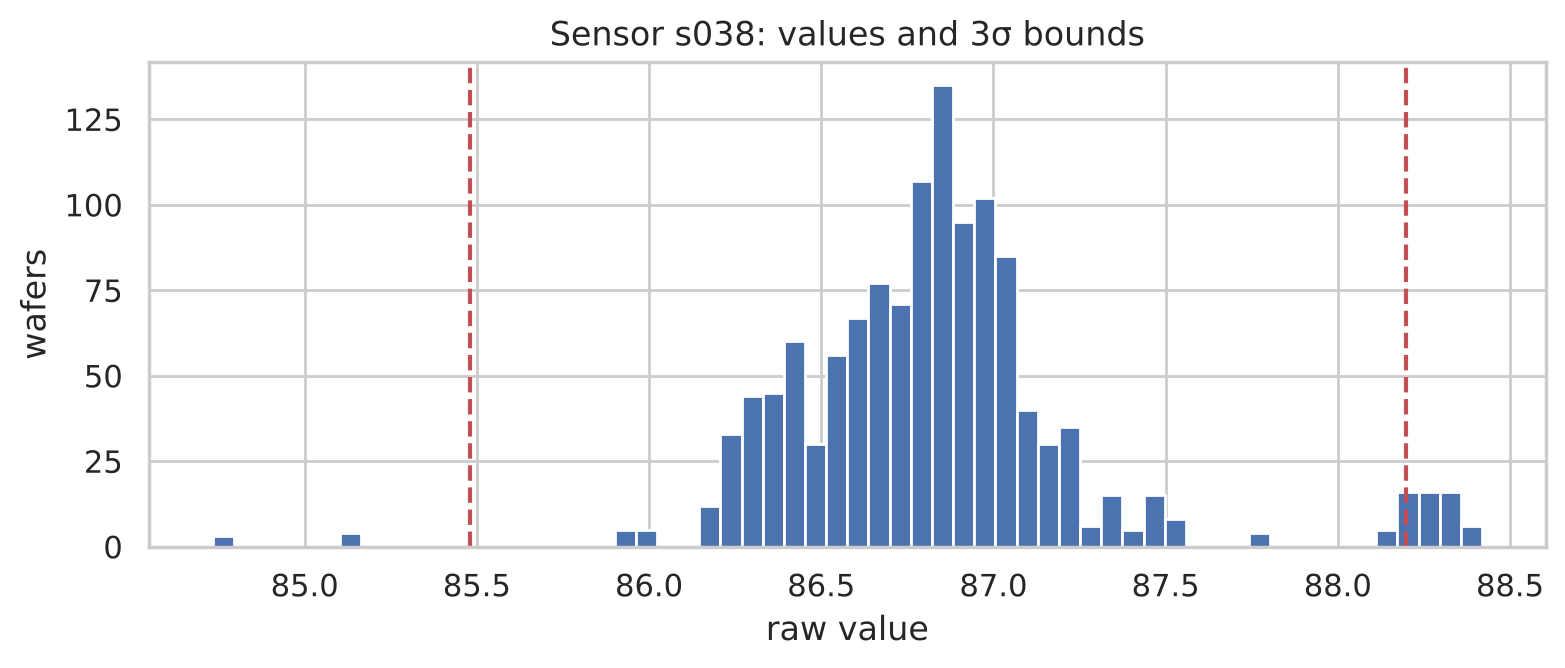

In [3]:
clipper = SigmaClipper(method="clip_bound").fit(X_f)
outside = X_f.lt(clipper.lower_, axis=1) | X_f.gt(clipper.upper_, axis=1)
n_out = outside.sum().sum()
print(f"values outside 3σ: {n_out:,} ({n_out / X_f.notna().sum().sum():.2%} of observed values)")

sensor = outside.sum().idxmax()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(X_f[sensor].dropna(), bins=60, color="#4C72B0")
for bound in (clipper.lower_[sensor], clipper.upper_[sensor]):
    ax.axvline(bound, color="#C44E52", ls="--")
ax.set(title=f"Sensor {sensor}: values and 3σ bounds", xlabel="raw value", ylabel="wafers")
fig.tight_layout()

## 3. Scaling and kNN imputation

Scaling comes first because kNN imputation is distance based: unscaled, the sensors with the largest
values would decide who counts as a "neighbour". Each missing value is replaced by the mean of its 5 nearest
wafers.

In [4]:
steps = dict(preprocessing_steps(best["outlier"], best["scaler"]))
X_o = steps["outliers"].fit_transform(X_f)
X_s = steps["scaler"].fit_transform(X_o)
X_i = steps["imputer"].fit_transform(X_s)
pd.DataFrame(
    {
        "features": [X.shape[1], X_f.shape[1], X_o.shape[1], X_i.shape[1]],
        "missing values": [
            X_train.isna().sum().sum(),
            X_f.isna().sum().sum(),
            X_o.isna().sum().sum(),
            X_i.isna().sum().sum(),
        ],
    },
    index=["raw", "after filter", f"after outliers ({best['outlier']})", f"after {best['scaler']} scaling + kNN"],
)

,features,missing values
raw,590,33868
after filter,450,11211
after outliers (none),450,11211
after robust scaling + kNN,450,0


## 4. Feature selection with Boruta

Boruta adds a shuffled "shadow" copy of every sensor, trains a Random Forest, and keeps only the sensors
that are repeatedly more important than the best shadow. Unlike PCA, it keeps the original sensors, so
engineers can look up exactly which signals matter.

In [5]:
boruta = BorutaSelector().fit(X_i, y_train)
selected = X_i.columns[boruta.support_]
tentative = X_i.columns[boruta.tentative_ & ~boruta.support_]
print(f"{X_i.shape[1]} sensors -> {len(selected)} confirmed, {len(tentative)} tentative")
print("confirmed:", ", ".join(selected))
print("tentative:", ", ".join(tentative) or "-")

450 sensors -> 15 confirmed, 3 tentative
confirmed: s031, s033, s059, s064, s065, s103, s130, s205, s213, s247, s319, s351, s477, s510, s519
tentative: s021, s125, s180


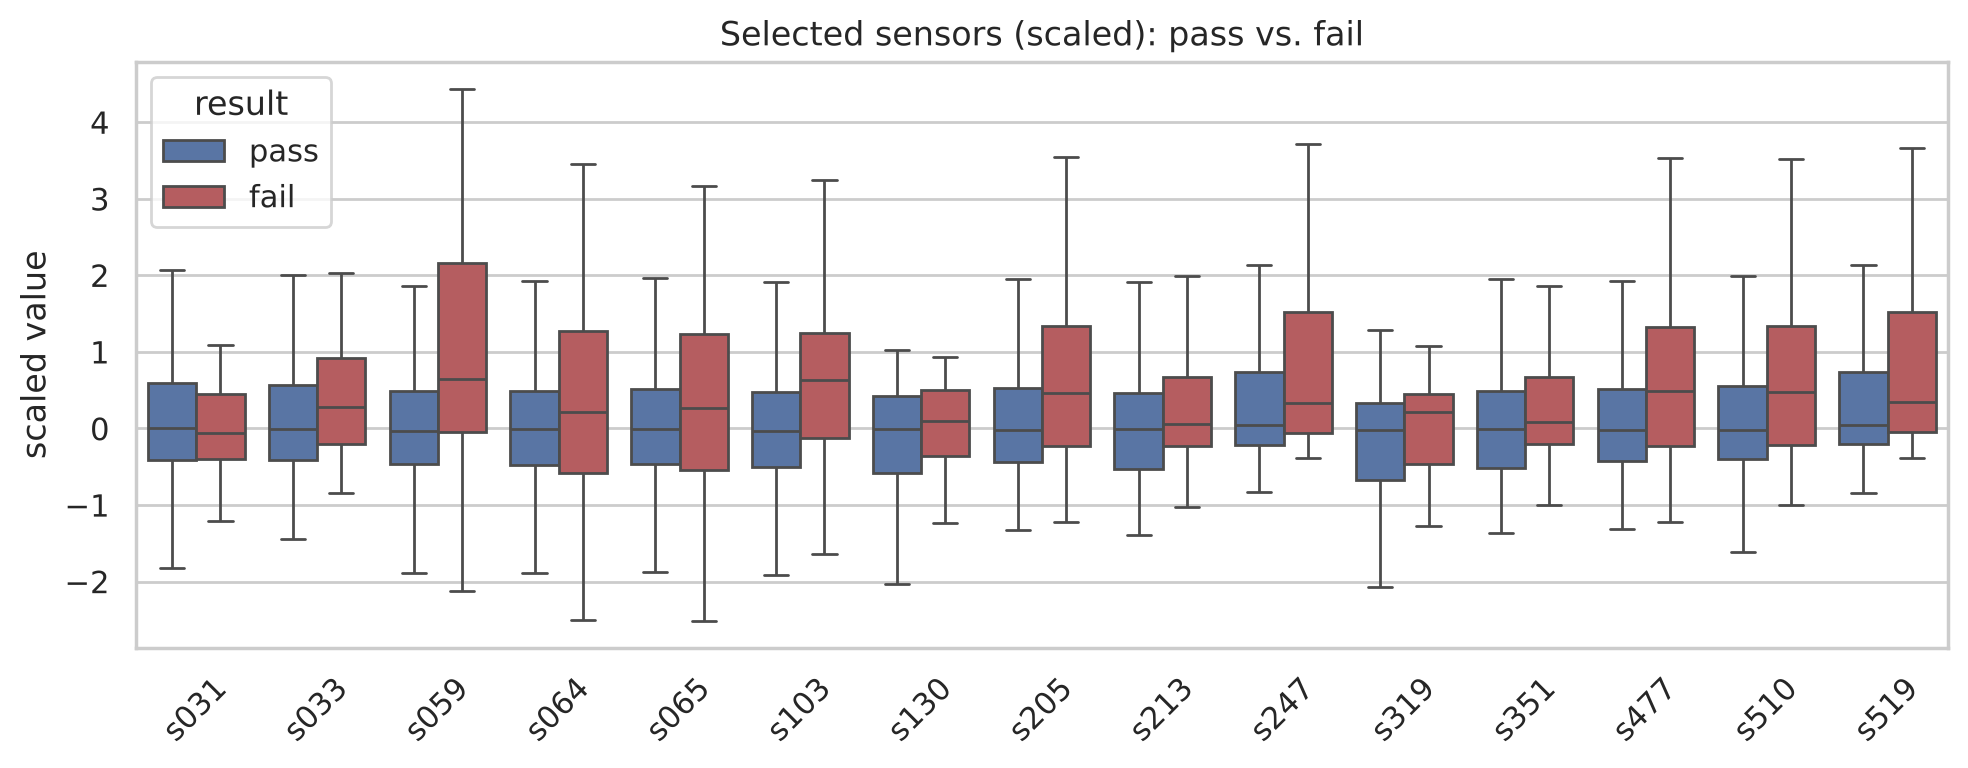

In [6]:
X_sel = X_i[selected]
fig, ax = plt.subplots(figsize=(10, 4))
data = X_sel.assign(result=y_train.map({0: "pass", 1: "fail"}).values).melt(id_vars="result", var_name="sensor")
sns.boxplot(
    data=data,
    x="sensor",
    y="value",
    hue="result",
    palette={"pass": "#4C72B0", "fail": "#C44E52"},
    showfliers=False,
    ax=ax,
)
ax.set(title="Selected sensors (scaled): pass vs. fail", ylabel="scaled value", xlabel="")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "selected_sensors_boxplot.png", dpi=150)

The shifts between passing and failing wafers are small and the distributions overlap heavily. This already
suggests that no model will separate the classes cleanly.

## 5. Oversampling the failures

Only 83 training wafers fail. Oversampling creates synthetic failures **in the training data only**; inside
the pipeline this happens per cross-validation fold, so validation folds keep the real class balance.

- **SMOTE** interpolates between a failure and one of its nearest failure neighbours.
- **ADASYN** does the same but focuses on failures that are hard to classify.
- **ROSE** draws failures with replacement and adds Gaussian noise (kernel bandwidth from Menardi & Torelli, 2014).

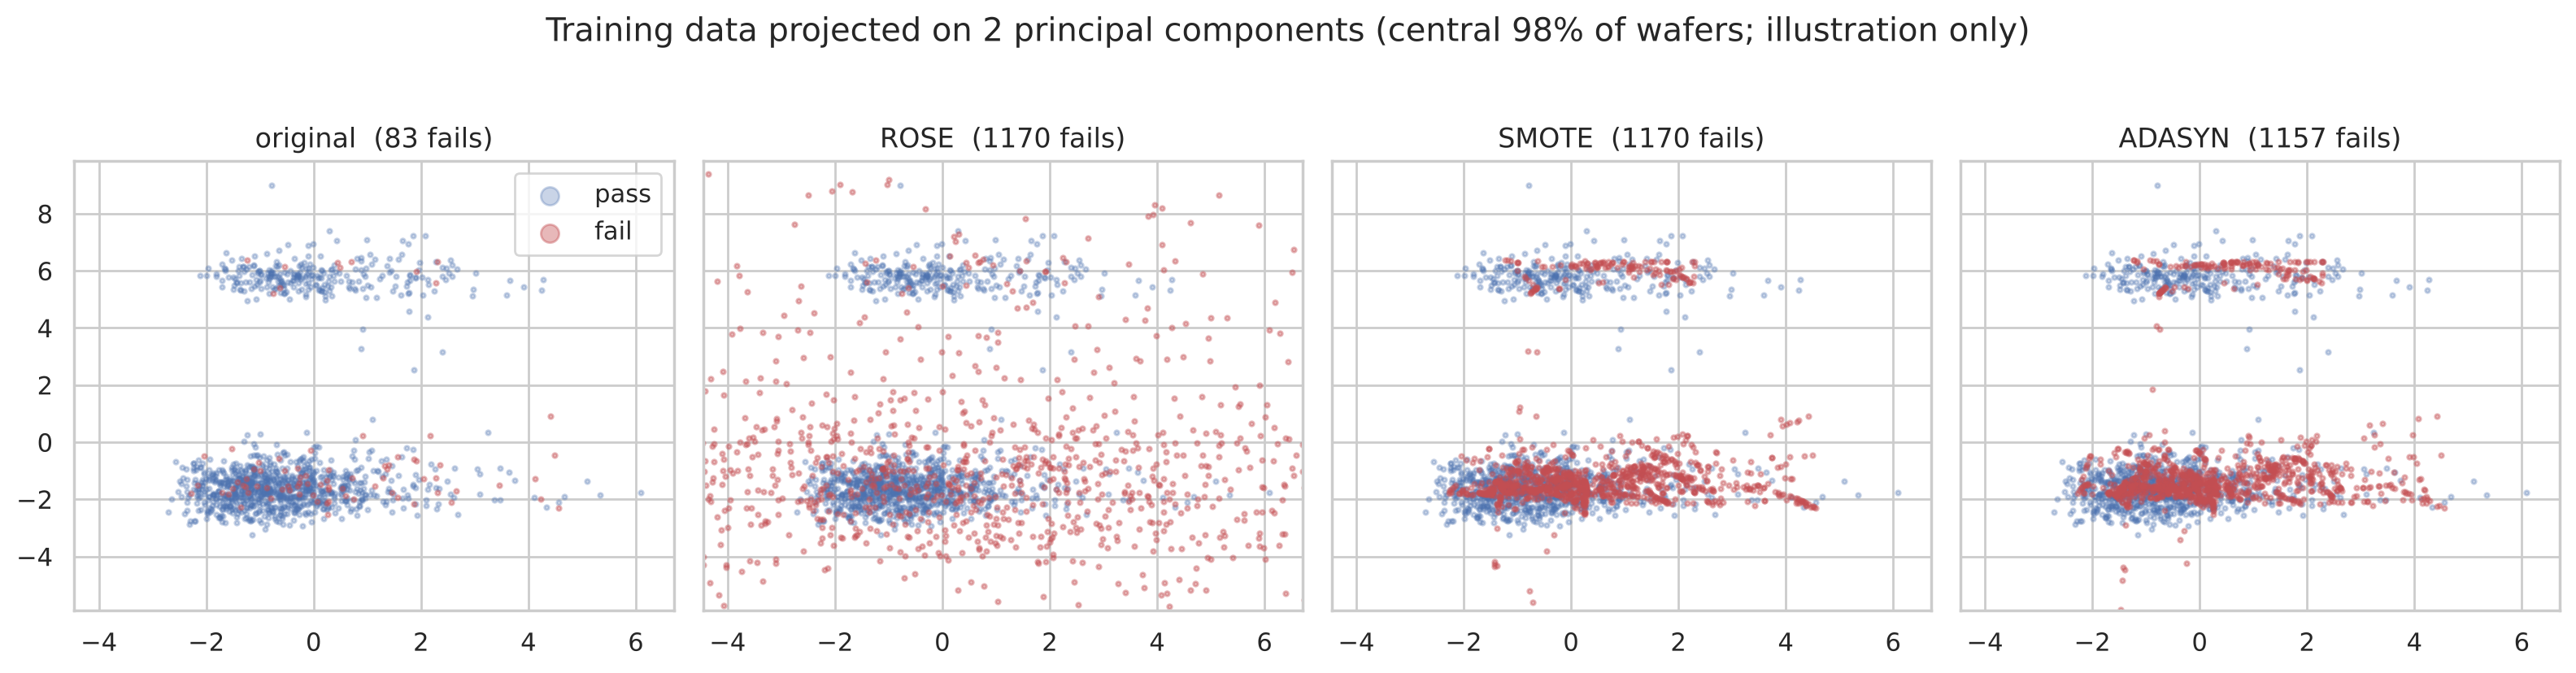

In [7]:
pca = PCA(n_components=2).fit(X_sel)
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
for ax, name in zip(axes, ["none", "rose", "smote", "adasyn"], strict=True):
    sampler = make_sampler(name)
    Xr, yr = (X_sel.to_numpy(), y_train.to_numpy()) if name == "none" else sampler.fit_resample(X_sel, y_train)
    Xr, yr = np.asarray(Xr), np.asarray(yr)
    P = pca.transform(pd.DataFrame(Xr, columns=selected))
    ax.scatter(*P[yr == 0].T, s=4, alpha=0.3, color="#4C72B0", label="pass")
    ax.scatter(*P[yr == 1].T, s=4, alpha=0.4, color="#C44E52", label="fail")
    ax.set_title(f"{'original' if name == 'none' else name.upper()}  ({(yr == 1).sum()} fails)")
P0 = pca.transform(X_sel)
lo, hi = np.percentile(P0, [1, 99], axis=0)
pad = (hi - lo) * 0.3
axes[0].set(xlim=(lo[0] - pad[0], hi[0] + pad[0]), ylim=(lo[1] - pad[1], hi[1] + pad[1]))
axes[0].legend(markerscale=4)
fig.suptitle("Training data projected on 2 principal components (central 98% of wafers; illustration only)", y=1.03)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "resampling_pca.png", dpi=150, bbox_inches="tight")

## 6. Steps considered but not applied

- **Power transforms (Box-Cox / Yeo-Johnson):** Random Forests make no normality assumption, so this would
  add work and reduce interpretability without improving predictions.
- **Dropping correlated sensors:** with unlabelled sensors there is no principled way to choose which of a
  correlated pair to keep; Boruta handles redundancy instead.

## Summary (Step Impact Protocol)

| Step | Decision | Effect on the training set |
|---|---|---|
| Train/test split | stratified 80/20 before any preprocessing | 1,253 train (83 fails), 314 test (21 fails) |
| Constant sensors | drop | 590 → 474 |
| Sensors > 60 % missing | drop | 474 → 450 |
| Outliers | chosen by CV (see notebook 03) | no rows removed |
| Scaling + imputation | scaler chosen by CV, kNN (k = 5) | 11,211 missing values filled |
| Feature selection | Boruta | 450 → a short list of sensors |
| Class balance | resampler chosen by CV, training folds only | test set keeps its real 6.6 % fail rate |

Next: [03 · Modeling and evaluation](03_modeling_evaluation.ipynb)